In [1]:
from pathlib import Path
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator
from CITNP.models.causalinferencemodel import CausalInferenceModel, LocalLatentCausalInferenceModel
import torch
from functools import partial
from CITNP.utils.datautils import transformer_inference_split_withpadding
from CITNP.trainer.causalinferencetrainer import send_to_device
import matplotlib.pyplot as plt
import numpy as np

In [2]:
model_path = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP/experiments/results/condgplvm_rzlayernorm_10enc_0dec_32samples/model_1.pt"
)

In [3]:
DATA_ARGS = {
    "sample_size": 1000,
    "num_variables": 2,
    "function_generator": "simplegplvm",
    "graph_type": ["ER"],
    "graph_degrees": [1],
    "iterations_per_epoch": 1,
    "batch_size": 1,
}

train_dataset = InterventionDatasetGenerator(**DATA_ARGS)
collator = partial(
    transformer_inference_split_withpadding,
    cntxt_split=[0.2, 0.8],
    sample_size=1000,
)
loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=None,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    persistent_workers=False,
    collate_fn=collator(),
)

In [4]:
from CITNP.utils.configs import LocalLatentConfig


MODEL_ARGS = {
    "d_model": 256,
    "emb_depth": 2,
    "decoder_depth": 0,
    "dim_feedforward": 1024,
    "nhead": 8,
    "dropout": 0.0,
    "num_layers_encoder": 10,
    "num_z_samples_train": 1,
    "num_z_samples_eval": 8,
    "num_nodes": 2,
    "device": "cpu",
    "dtype": torch.float32,
}
config = LocalLatentConfig(**MODEL_ARGS)

model = LocalLatentCausalInferenceModel(config=config)
model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

In [7]:
from CITNP.utils.configs import CausalInfModelConfig


MODEL_ARGS = {
    "d_model": 256,
    "emb_depth": 2,
    "dim_feedforward": 1024,
    "nhead": 8,
    "dropout": 0.0,
    "num_layers_encoder": 10,
    "num_nodes": 2,
    "device": "cpu",
    "dtype": torch.float32,
}
config = CausalInfModelConfig(**MODEL_ARGS)

model = CausalInferenceModel(config=config)
model.load_state_dict(torch.load(model_path))

RuntimeError: Error(s) in loading state_dict for CausalInferenceModel:
	Unexpected key(s) in state_dict: "z_param_mean_mlp.0.weight", "z_param_mean_mlp.0.bias", "z_param_mean_mlp.2.weight", "z_param_mean_mlp.2.bias", "z_param_std_mlp.0.weight", "z_param_std_mlp.0.bias", "z_param_std_mlp.2.weight", "z_param_std_mlp.2.bias", "z_rep_merger.layernormQ.weight", "z_rep_merger.layernormQ.bias", "z_rep_merger.layernormK.weight", "z_rep_merger.layernormK.bias", "z_rep_merger.layernormV.weight", "z_rep_merger.layernormV.bias", "z_rep_merger.q_proj.weight", "z_rep_merger.k_proj.weight", "z_rep_merger.v_proj.weight", "z_rep_merger.out_proj.weight". 

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0


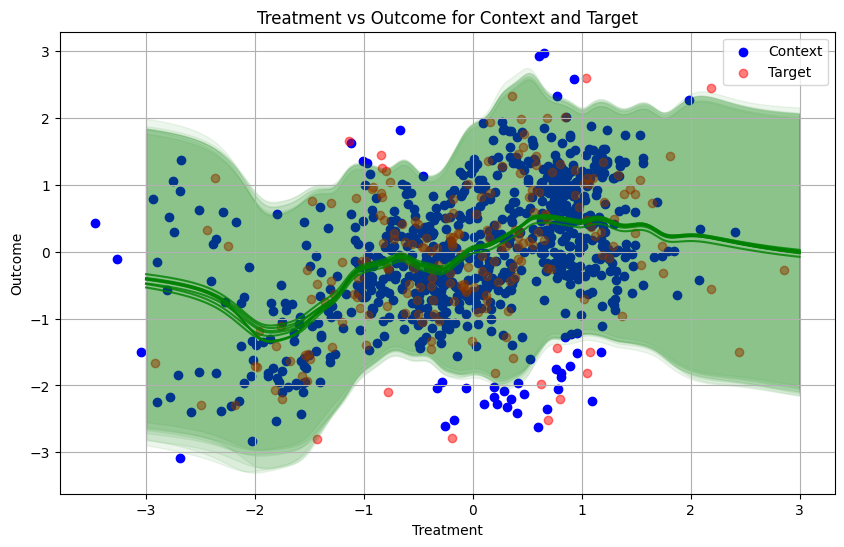

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1


<Figure size 640x480 with 0 Axes>

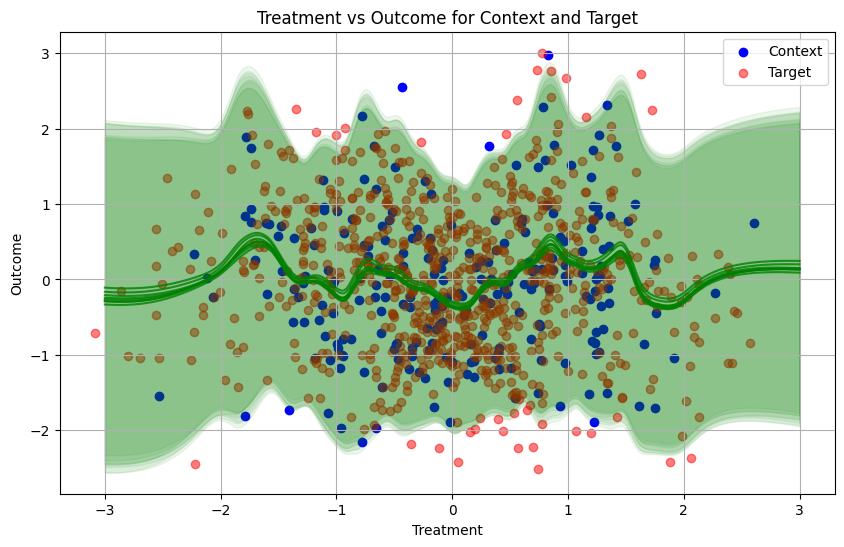

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0


<Figure size 640x480 with 0 Axes>

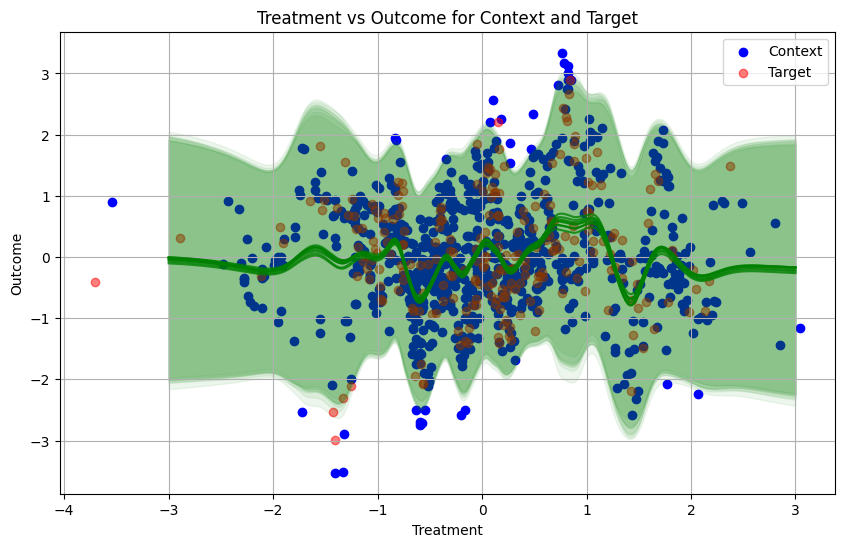

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0


<Figure size 640x480 with 0 Axes>

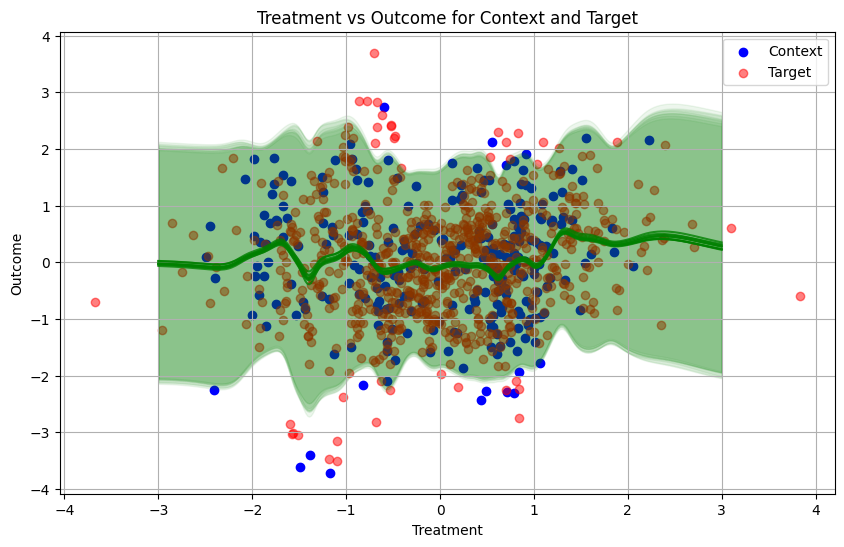

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1


<Figure size 640x480 with 0 Axes>

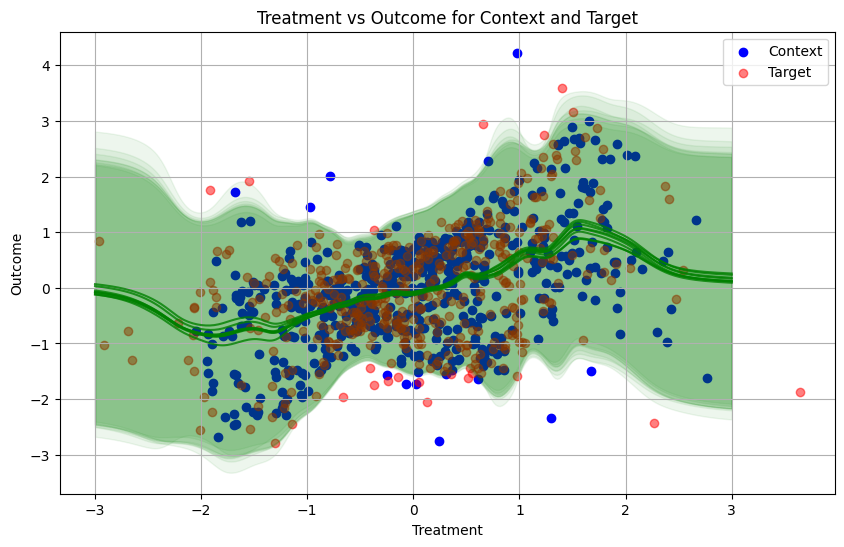

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1


<Figure size 640x480 with 0 Axes>

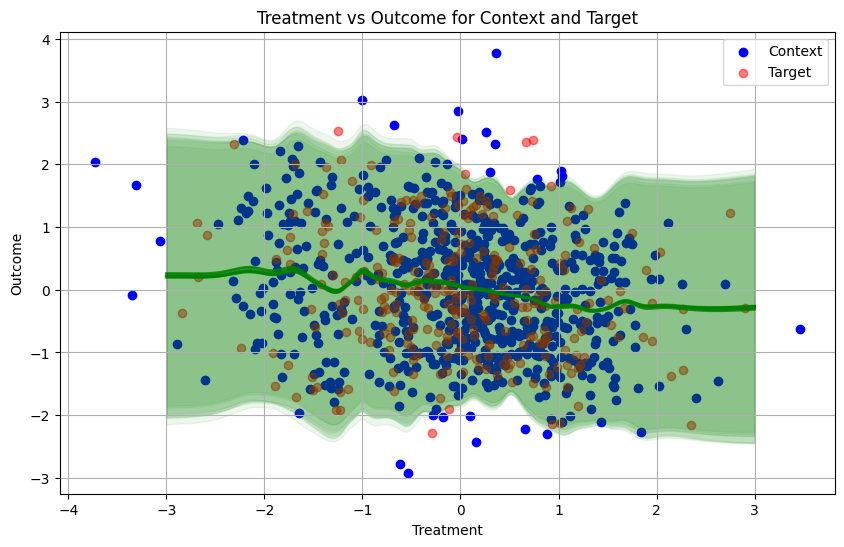

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1


<Figure size 640x480 with 0 Axes>

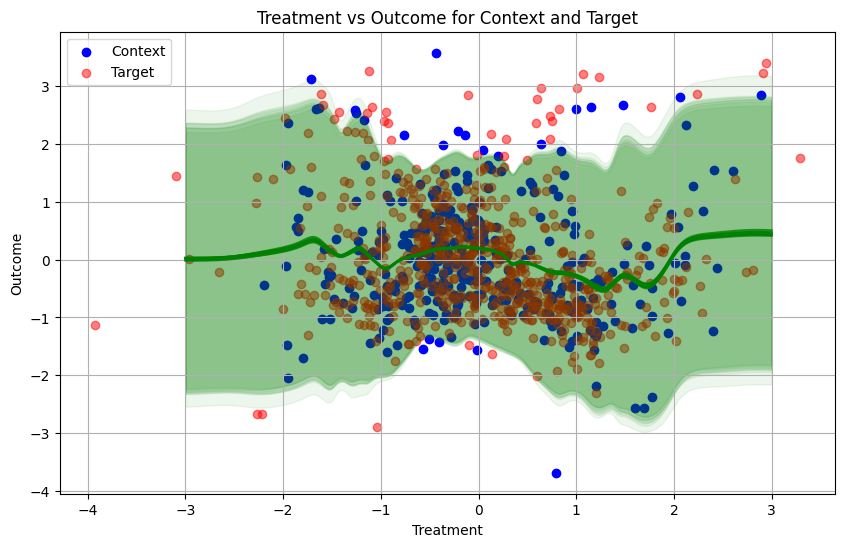

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1


<Figure size 640x480 with 0 Axes>

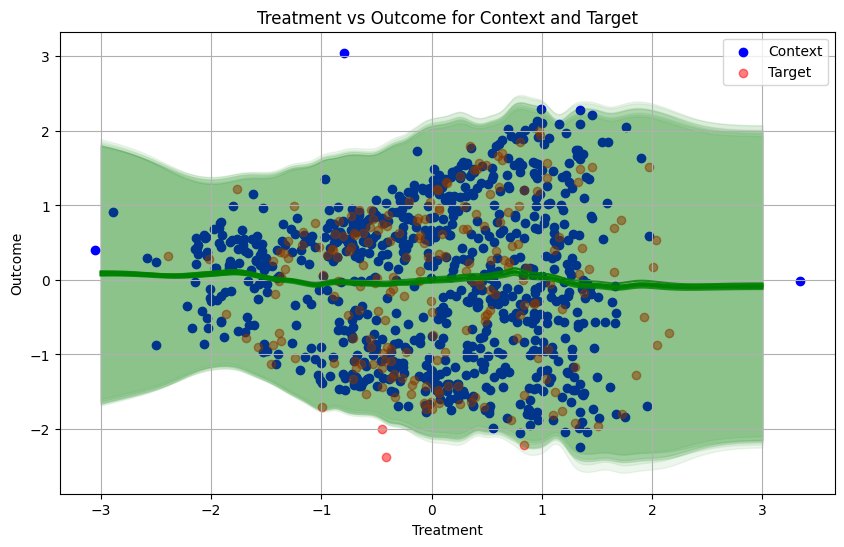

tensor([[0., 0.],
        [1., 0.]], device='cuda:0')
Intervention: 1
Outcome: 0


<Figure size 640x480 with 0 Axes>

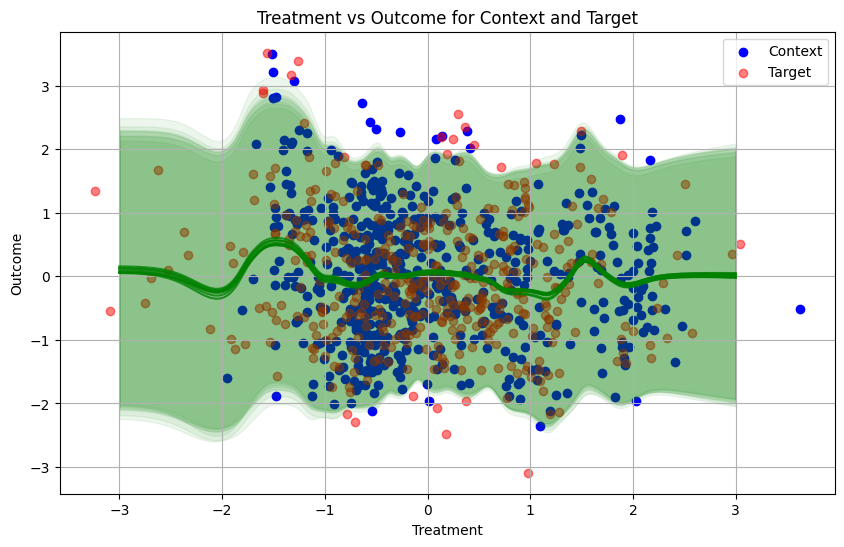

tensor([[0., 1.],
        [0., 0.]], device='cuda:0')
Intervention: 0
Outcome: 1


<Figure size 640x480 with 0 Axes>

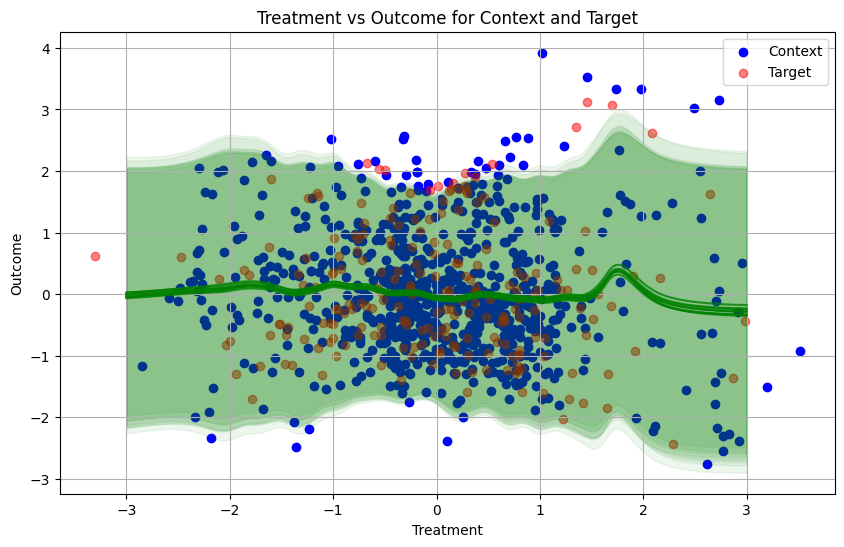

<Figure size 640x480 with 0 Axes>

In [5]:
from CITNP.utils.plotting import plot_context_target_predictions


DEVICE = "cuda"

model.eval()
model.to(DEVICE)
for iteration in range(10):
    for batch in loader:
        context, target, intvn_indices, outcome_indices, masks, graph = (
            send_to_device(
                list(batch),
                device=DEVICE,
            )
        )
        new_target = (
            torch.linspace(-3, 3, 300).unsqueeze(1).repeat(1, 2)[None, :, :, None]
        )
        new_target = new_target.to(DEVICE)
        mean, std, _, _ = model(
            context_data=context,
            target_data=new_target,
            intervention_index=intvn_indices,
            outcome_index=outcome_indices,
            variable_mask=None,
        )
        print(graph[0])
        print(f"Intervention: {intvn_indices[0]}")
        print(f"Outcome: {outcome_indices[0]}")
        if mean.ndim == 3:
            mean = mean.unsqueeze(0)
            std = std.unsqueeze(0)
        plot_context_target_predictions(
            context=context,
            target=target,
            new_target=new_target,
            pred_mean=mean,
            pred_std=std,
            treatment_idx=intvn_indices,
            outcome_index=outcome_indices,
        )

In [6]:
mean.shape

torch.Size([8, 1, 300, 1])

In [ ]:
mean.shape

In [ ]:
mean.shape

In [ ]:
new_target = torch.linspace(-3, 3, 500).unsqueeze(1).repeat(1, 2)

In [ ]:
new_target.shape

In [ ]:
target.shape